# TweetAge v5 – Modelos de lenguaje n-grama por clase, cinco particiones y promedio de semillas
**Curso de Procesamiento del Lenguaje Natural · Maestría en Inteligencia Artificial · Pontificia Universidad Javeriana**

Equipo: ____________________

Sin modelos preentrenados, sin embeddings y sin redes: todo se aprende desde cero con `age_train.csv`.

## Evolución de los resultados

| Versión | Modelo | F1 macro validación (80/20, semilla 42) | F1 macro Kaggle |
|---|---|---|---|
| v1 | SVM lineal sobre TF-IDF con vocabulario limitado | 0,555 | 0,56175 |
| v2 | NB-SVM sobre palabras 1-3 + caracteres 2-5 y 1-5 | 0,581 | — |
| v3 | NB-SVM + homofilia de red (G6) + meta-modelo de gradient boosting | 0,607 | 0,61765 |
| v4 | v3 + homofilia ampliada + modelos base diversos + estilo + pesos por clase | 0,619 | por medir |
| **v5** | **v4 + LM n-grama Kneser-Ney por clase + 5 particiones + 3 semillas** | **0,6265** | por medir |

## Qué cambia respecto a la v4
1. **Modelos de lenguaje n-grama por clase** (nuevo bloque de entradas): un LM de caracteres de orden 5 y uno de palabras de orden 3 para cada grupo de edad, con suavizado Kneser-Ney interpolado. Cada uno da la log-verosimilitud del tweet bajo cada clase; esas seis puntuaciones entran al meta-modelo, calculadas fuera de muestra.
2. **`K_FOLDS` de 3 a 5**: los modelos base se entrenan con el 80 % del ajuste (antes el 67 %), y sus puntuaciones fuera de muestra se parecen más a las que verá el test.
3. **Meta-modelo promediado sobre 3 semillas**: la parada temprana del gradient boosting reserva un 10 % aleatorio; promediar tres semillas reduce esa varianza.
4. **Semillas fijas en todo**: `LinearSVC(random_state=SEED)` (v4 no la fijaba) y versiones de librerías registradas.
5. **Pesos por clase**: la misma búsqueda de v4, ahora sobre las probabilidades promediadas.

Lo demás (limpieza, G6, H5, G0, TF-IDF, NB-SVM, ComplementNB, hiperparámetros del gradient boosting) es idéntico a la v4.

## Ablación v4 → v5 (validación 80/20, semilla 42, misma corrida)

| Paso | F1 macro | Cambio |
|---|---|---|
| v4: K=3, 1 semilla | 0,6179 | — |
| v4 + pesos por clase (**referencia v4**) | **0,6193** | +0,0014 |
| K_FOLDS = 5 | 0,6193 | 0,0000 |
| + LM n-grama (caracteres 5, palabras 3) | 0,6231 | +0,0039 |
| + meta-modelo promediado en 3 semillas | 0,6245 | +0,0014 |
| + pesos por clase (**modelo v5**) | **0,6265** | +0,0020 |
| + pseudo-etiquetas (τ = 0,90; 8 767 tweets) — *descartado* | 0,6263 | −0,0002 |

LM usados solos (log-verosimilitud + prior): caracteres 0,5669 · palabras 0,5148.

**Tabla de ablación en la validación 80/20 (semilla 42):** sección 7. **Decisiones de diseño:** se tomaron en una **partición de desarrollo separada** (sección 7.1), nunca mirando la validación.

**Tiempo medido:** 25 min (validación con referencia v4 pareada: 15 min; modelo final: 10 min) en un Mac de 18 núcleos con `VALIDAR=True`. Memoria máxima medida: 7,7 GB.

## 1. Librerías y configuración

Solo `numpy`, `pandas`, `scipy`, `scikit-learn` y `matplotlib`. Los LM n-grama están implementados a mano con `numpy`.

| Parámetro | Valor | Significado |
|---|---|---|
| `ALLOW_TFIDF` | `True` | El profesor aclaró por correo que TF-IDF está permitido. Si la confirmación para TweetAge no llega, con `False` se apagan los tres modelos base sobre TF-IDF (NB, nbword, cnb) y quedan homofilia, estilo y los LM |
| `VALIDAR` | `True` | Repite todo en el holdout 80/20 y muestra la ablación antes del modelo final |
| `ABLACION_V4` | `True` | Recalcula en la misma corrida la v4 con 3 particiones, para que la comparación v4 vs v5 sea pareada (+3-4 min) |
| `DESARROLLO` | `False` | Repite las pruebas de la partición de desarrollo con las que se tomaron las decisiones (+8 min) |
| `SAMPLE_FRAC` | `None` | Fracción del train para probar el código rápido; no sirve para Kaggle |
| `K_FOLDS` | 5 | Particiones para las entradas fuera de muestra (v4: 3) |
| `META_SEEDS` | 0, 1, 2 | Semillas del meta-modelo que se promedian (la 0 es la de v4) |
| `LM_SPECS` | caracteres 5, palabras 3 | Modelos de lenguaje por clase: (nombre, nivel, orden, frecuencia mínima del vocabulario) |
| `PSEUDO_TAU`, `PSEUDO_MIN_GAIN` | 0,90 y 0,002 | Umbral de confianza del pseudo-etiquetado y ganancia mínima en validación para aplicarlo (sección 8) |
| `NB_ALPHA`, `SVM_C`, `HGB_PARAMS` | como en v4 | Sin cambios |

In [1]:
import os, re, sys, html, time, gc, random, platform, warnings
import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt
import scipy, sklearn
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')

ALLOW_TFIDF = True     # TF-IDF permitido según el correo del profesor; False lo desactiva
VALIDAR     = True
ABLACION_V4 = True
DESARROLLO  = False
SAMPLE_FRAC = None
SEED        = 42
K_FOLDS     = 5
META_SEEDS  = [0, 1, 2]
LM_SPECS    = [('lm_car', 'char', 5, 3), ('lm_pal', 'word', 3, 2)]
PSEUDO_TAU  = 0.90
PSEUDO_MIN_GAIN = 0.002   # ganancia mínima en validación para aplicarlo (ruido entre semillas de v4: ±0,0015)
NB_ALPHA, SVM_C = 1.0, 0.3
HGB_PARAMS  = dict(max_iter=300, learning_rate=0.06, max_leaf_nodes=63, min_samples_leaf=50,
                   l2_regularization=1.0, random_state=0)
OUT_PATH    = 'age_submission_v5.csv'

random.seed(SEED); np.random.seed(SEED)
CANDIDATE_DIRS = [os.getcwd(), os.path.join(os.getcwd(), 'data'), os.path.join(os.getcwd(), 'tweet-age-2026-puj'),
                  r'/kaggle/input/tweet-age-2026-puj', r'C:\Users\leonk\Documents\MINTA 2025-01\PLN']
DATA_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(os.path.join(d, 'age_train.csv'))), None)
assert DATA_DIR, 'No encontré age_train.csv: agregue su carpeta a CANDIDATE_DIRS.'

GROUPS = np.array(['13-17', '18-24', '25-34', '35-49', '50-64', '65-xx'])
T0 = time.time()
def log(*m): print(f'[{time.time() - T0:6.0f}s]', *m, flush=True)
def peak_gb():
    try:
        import resource
        r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        return r / (1024 ** 3 if sys.platform == 'darwin' else 1024 ** 2)
    except ImportError:
        return float('nan')
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| scipy', scipy.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)
log('Datos en:', DATA_DIR)

Python 3.12.14 | numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2
[     0s] Datos en: /Users/abelalbuez/Documents/Maestria/Cuarto Semestre/PLN/natural-language-processing-workshops/workshops/Kaggle-tweet-age/tweet-age-2026-puj


## 2. Lectura y limpieza mínima

Igual que en las versiones anteriores: separador `;`, BOM, relleno de espacios y entidades HTML decodificadas. Del entrenamiento se excluyen los tweets vacíos y el artefacto `#¿NOMBRE?`. No se eliminan stopwords, menciones, mayúsculas ni alargamientos, porque son marcas de edad.

In [2]:
def load(path):
    df = pd.read_csv(path, sep=';', encoding='utf-8-sig', dtype=str, keep_default_na=False)
    df['text'] = df['text'].str.strip().map(html.unescape)
    return df

def is_junk(texts):
    t = pd.Series(texts)
    return ((t == '') | t.str.contains('#¿NOMBRE', regex=False)).values

train_raw = load(os.path.join(DATA_DIR, 'age_train.csv'))
test = load(os.path.join(DATA_DIR, 'age_test.csv'))
if SAMPLE_FRAC:
    train_raw = train_raw.groupby('age_range', group_keys=False).sample(frac=SAMPLE_FRAC, random_state=SEED)
train = train_raw[~is_junk(train_raw.text)].reset_index(drop=True)
log(f'train {train.shape} | test {test.shape}')

[     0s] train (169181, 3) | test (112892, 2)


## 3. Modelos base (nivel 1)

### 3.1 Modelos sobre TF-IDF (de la v4)
El sistema tiene dos niveles. En el primero, varios modelos de texto producen **puntuaciones por clase**; en el segundo, un meta-modelo las combina con otras variables.

**Representación:** los tres bloques TF-IDF de la v2/v3, sin límite de vocabulario: palabras 1-3 (con `@usuarios` y `#hashtags`), caracteres 2-5 dentro de palabra (`char_wb`) y caracteres 1-5 que cruzan palabras (`char`).

Solo se activan con `ALLOW_TFIDF = True`.

**Tres modelos base, que se equivocan de forma distinta:**
1. **NB-SVM completo** (Wang & Manning, 2012) sobre los tres bloques: un SVM por clase con cada término ponderado por su log-cociente de Naive Bayes, $r_c = \log\frac{(p+\alpha)/\lVert p+\alpha\rVert_1}{(q+\alpha)/\lVert q+\alpha\rVert_1}$.
2. **NB-SVM solo de palabras** *(nuevo en v4)*: ve únicamente vocabulario, cuentas y hashtags, sin la influencia de los n-gramas de caracteres.
3. **ComplementNB** *(nuevo en v4)*: Naive Bayes que estima cada clase con los documentos de las *otras* clases, más estable en texto (Rennie et al., 2003). Es un modelo probabilístico, no de márgenes como el SVM.

Darle al meta-modelo puntuaciones de modelos distintos le permite aprender **cuándo confiar en cada uno** (*stacking*; Wolpert, 1992).

**Cambios respecto a la v4 (no alteran el método):** `LinearSVC` recibe `random_state=SEED` (en la v4 no estaba fija y dos corridas podían diferir en ±0,001). Además, el escalado por el log-cociente se hace directamente en float64 (`scale_cols`), el tipo que liblinear usa por dentro, y el TF-IDF de aplicación se calcula después de las particiones. Así se evitan copias de una matriz de 100 millones de valores no nulos y el pico de memoria con `K_FOLDS = 5` baja de unos 10 GB a unos 7 GB.

In [3]:
def make_vectorizers():
    return [TfidfVectorizer(token_pattern=r'(?u)[@#]?\w+', ngram_range=(1, 3), min_df=2, sublinear_tf=True, dtype=np.float32),
            TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=3, lowercase=False, sublinear_tf=True, dtype=np.float32),
            TfidfVectorizer(analyzer='char', ngram_range=(1, 5), min_df=5, lowercase=False, sublinear_tf=True, dtype=np.float32)]

def scale_cols(X, r):
    """X @ diag(r) directamente en float64 (el tipo que exige liblinear), compartiendo los índices de X: evita dos copias de la matriz."""
    return sparse.csr_matrix(((X.data * r[X.indices]).astype(np.float64), X.indices, X.indptr), shape=X.shape)

def nbsvm_fit(Xfit, yfit):
    """Un SVM binario por clase sobre columnas escaladas por el log-cociente de Naive Bayes."""
    models = []
    for c in GROUPS:
        pos = yfit == c
        p = np.asarray(pos.astype(np.float64) @ Xfit).ravel() + NB_ALPHA      # suma por columna sin copiar filas
        q = np.asarray((~pos).astype(np.float64) @ Xfit).ravel() + NB_ALPHA
        r = np.log((p / p.sum()) / (q / q.sum())).astype(np.float32)
        models.append((r, LinearSVC(C=SVM_C, random_state=SEED).fit(scale_cols(Xfit, r), pos.astype(int))))
    return models

def nbsvm_apply(models, Xapp):
    return np.column_stack([m.decision_function(scale_cols(Xapp, r)) for r, m in models]).astype(np.float32)

def nbsvm_scores(Xfit, yfit, Xapp): return nbsvm_apply(nbsvm_fit(Xfit, yfit), Xapp)

def cnb_fit(Xfit, yfit):
    m = ComplementNB(alpha=0.3).fit(Xfit, yfit)
    assert list(m.classes_) == list(GROUPS)
    return m

def cnb_scores(Xfit, yfit, Xapp): return cnb_fit(Xfit, yfit).predict_log_proba(Xapp).astype(np.float32)

### 3.2 Modelos de lenguaje n-grama por clase *(nuevo en v5)*
Para cada grupo de edad $c$ se entrena un modelo de lenguaje con los tweets de esa clase y se clasifica con la regla de Bayes:

$$\hat c = \arg\max_c \; \log P(c) + \sum_i \log P_c(w_i \mid w_{i-N+1} \ldots w_{i-1})$$

Es el enfoque de "un modelo de lenguaje por autor" para atribución de autoría y perfilado (Peng et al., 2003): cada grupo de edad tiene su propia forma de escribir, y el modelo que mejor "predice" el tweet indica a qué grupo se parece.

**Dos niveles:**
- **Caracteres, orden 5** (contextos de hasta 4 caracteres, interpola los órdenes 1 a 5): conserva mayúsculas, alargamientos, emojis y `@cuentas`. Las URL se reemplazan por un solo símbolo, porque el código `t.co` es aleatorio (H5 ya lo aprovecha). Caracteres con menos de 3 apariciones pasan a `UNK`.
- **Palabras, orden 3** (interpola uni-, bi- y trigramas): minúsculas, `@cuentas` y `#hashtags` como palabras, signos separados. Palabras con menos de 2 apariciones pasan a `UNK`.

**Suavizado Kneser-Ney interpolado** (Kneser & Ney, 1995; Chen & Goodman, 1999):

$$P(w\mid h) = \frac{\max(c(hw) - D, 0)}{c(h)} + \frac{D\,N_{1+}(h\,\bullet)}{c(h)}\,P(w \mid h')$$

donde $h'$ es el contexto acortado. En los órdenes inferiores $c(\cdot)$ se reemplaza por el **conteo de continuación** $N_{1+}(\bullet\,h w)$: cuántos contextos distintos preceden al n-grama. El descuento de cada orden y clase se estima como $D = n_1/(n_1 + 2n_2)$, con $n_1$ y $n_2$ los n-gramas vistos una y dos veces. El orden 1 se interpola con la distribución uniforme, así que ningún símbolo tiene probabilidad cero. Si un contexto no se vio en la clase, se usa directamente el orden inferior. Una prueba al final de la celda comprueba que las probabilidades suman 1.

**Implementación:** cada n-grama se codifica como un entero de 64 bits; los conteos salen de `np.unique` y las consultas de búsquedas binarias. Seis clases × cinco particiones tardan menos de un minuto.

**Qué entra al meta-modelo:** para cada LM, la log-verosimilitud **por símbolo** de cada clase menos la media de las seis clases. Dividir por la longitud evita que los tweets largos tengan puntuaciones extremas. Las puntuaciones del ajuste son fuera de muestra (cada tweet se puntúa con LM que no vieron su etiqueta).

> **Qué no se usó:** Witten-Bell (Kneser-Ney se prefiere en la literatura para n-gramas de orden alto; Chen & Goodman, 1999). Tampoco redes ni embeddings entrenados desde cero: la red tipo fastText que proponía la v4 aprende embeddings de palabras, y los embeddings de cualquier tipo están prohibidos, así que se descartó.

In [4]:
URL_RE = re.compile(r'https?://\S+')
WORD_RE = re.compile(r'[@#]?\w+|[^\w\s]')
BOS, EOS, UNK = 0, 1, 2                                   # símbolos reservados; el vocabulario empieza en 3

def lm_sequences(texts, level):
    """Cada tweet como lista de símbolos: caracteres (con mayúsculas) o palabras en minúscula. Las URL pasan a un solo símbolo."""
    if level == 'char':
        return [list(URL_RE.sub('\x01', t)) for t in texts]
    return [WORD_RE.findall(URL_RE.sub(' urlurl ', t.lower())) for t in texts]

def lm_encode(seqs_fit, seqs_app, N, min_count):
    """Códigos enteros de los N-gramas de cada posición (con N-1 BOS y un EOS por tweet). El vocabulario sale solo de T_fit."""
    cnt = {}
    for s in seqs_fit:
        for x in s: cnt[x] = cnt.get(x, 0) + 1
    vocab = {x: i + 3 for i, x in enumerate(sorted(k for k, v in cnt.items() if v >= min_count))}
    V = len(vocab) + 3
    assert float(V) ** N < 2 ** 62, 'vocabulario demasiado grande para codificar en int64'
    def codes(seqs):
        ids = [[BOS] * (N - 1) + [vocab.get(x, UNK) for x in s] + [EOS] for s in seqs]
        lens = np.array([len(s) for s in ids]); S = np.fromiter((x for s in ids for x in s), np.int64, lens.sum())
        pos = np.flatnonzero(S != BOS)                    # posiciones que se predicen (todo menos los BOS)
        g = np.zeros(len(pos), np.int64)
        for j in range(N - 1, -1, -1): g = g * V + S[pos - j]
        return g, np.repeat(np.arange(len(ids)), lens - (N - 1))
    gf, df = codes(seqs_fit); ga, da = codes(seqs_app)
    return gf, df, ga, da, V

class KneserNey:
    """Kneser-Ney interpolado (Chen & Goodman, 1999) de orden N sobre códigos enteros de N-gramas.
    El orden más alto usa frecuencias; los inferiores, conteos de continuación N1+(·h w). Descuento D = n1 / (n1 + 2 n2) por orden."""
    def __init__(self, g, V, N):
        self.V, self.N, self.P = V, N, [V ** k for k in range(N + 1)]
        u, c = np.unique(g, return_counts=True)
        self.tab = {}
        for k in range(N, 0, -1):
            n1, n2 = (c == 1).sum(), (c == 2).sum(); D = n1 / max(n1 + 2 * n2, 1) if n1 else 0.5
            h, idx = np.unique(u // V, return_index=True)  # u está ordenado, así que u // V también
            den = np.add.reduceat(c, idx).astype(np.float64); n1p = np.diff(np.append(idx, len(u))).astype(np.float64)
            self.tab[k] = (u, c.astype(np.float64), h, den, n1p, D)
            if k > 1: u, c = np.unique(u % self.P[k - 1], return_counts=True)   # continuación: tipos distintos que terminan en el sufijo
        self.n_tot, self.n_types = self.tab[1][1].sum(), len(self.tab[1][0])

    @staticmethod
    def _look(keys, vals, q):
        i = np.minimum(np.searchsorted(keys, q), len(keys) - 1); hit = keys[i] == q
        return np.where(hit, vals[i], 0.0), hit

    def logprob(self, q):
        u, c, _, _, _, D = self.tab[1]
        cw, _ = self._look(u, c, q % self.V)
        p = (np.maximum(cw - D, 0) + D * self.n_types / (self.V - 1)) / self.n_tot   # reparto uniforme sobre todo símbolo predecible (no BOS)
        for k in range(2, self.N + 1):
            u, c, h, den, n1p, D = self.tab[k]
            qk = q % self.P[k]
            cw, _ = self._look(u, c, qk); dh, hit = self._look(h, den, qk // self.V); nh, _ = self._look(h, n1p, qk // self.V)
            p = np.where(hit, (np.maximum(cw - D, 0) + D * nh * p) / np.maximum(dh, 1e-12), p)
        return np.log(p)

def lm_scores(gf, df, yf_doc, ga, da, n_app, V, N):
    """Log-verosimilitud de cada tweet de aplicación bajo el LM de cada clase, ajustado solo con los tweets de ajuste."""
    q, inv = np.unique(ga, return_inverse=True)
    yp = yf_doc[df]
    L = np.zeros((n_app, len(GROUPS)), np.float64)
    for ci, c in enumerate(GROUPS):
        lp = KneserNey(gf[yp == c], V, N).logprob(q)
        L[:, ci] = np.bincount(da, weights=lp[inv], minlength=n_app)
    return L

# Prueba: en cualquier contexto, la suma de P(w | h) sobre todos los símbolos predecibles es 1.
_s = lm_sequences(['hola mundo', 'hola hola', 'mundo feliz', 'adiós'], 'char')
for _N in (1, 3, 5):
    _g, _, _, _, _V = lm_encode(_s, _s, _N, 1); _m = KneserNey(_g, _V, _N)
    for _h in (_g[0] // _V, _g[5] // _V, 7 % (_V ** (_N - 1)) if _N > 1 else 0):
        assert abs(np.exp(_m.logprob(np.arange(1, _V, dtype=np.int64) + _h * _V)).sum() - 1) < 1e-9
log('Prueba de normalización de Kneser-Ney superada')

[     0s] Prueba de normalización de Kneser-Ney superada


## 4. Variables para el meta-modelo

### 4.1 G6: homofilia de red de la v3
Para cada `@cuenta` y cada `#hashtag` se calcula la distribución de edades de los tweets de entrenamiento que la contienen (*target encoding*; Micci-Barreca, 2001). Las distribuciones de las cuentas del tweet se suman y se suavizan hacia la distribución global con `prior=10`, para que una cuenta vista una sola vez no domine. Se basa en la **homofilia**: las personas se relacionan con quienes se les parecen (McPherson et al., 2001), y en Twitter eso permite inferir atributos a partir de la red (Al Zamal et al., 2012).

In [5]:
def encode_entities(tok_fit, y_fit, tok_app, prefix, prior=10.0):
    """Codificación por objetivo: tok_* son listas de entidades por tweet (o textos si se usa token_pattern)."""
    if isinstance(prefix, tuple):                      # (patrón regex, prefijo): extrae entidades del texto
        pat, prefix = prefix
        cv = CountVectorizer(token_pattern=pat, lowercase=True, binary=True)
    else:
        cv = CountVectorizer(analyzer=lambda x: x, binary=True)
    Xf, Xp = cv.fit_transform(tok_fit), cv.transform(tok_app)
    Y = (np.asarray(y_fit)[:, None] == GROUPS[None, :]).astype(np.float32)
    C = np.asarray(Xf.T @ Y)                          # conteo de tweets por entidad y grupo de edad
    glob = Y.mean(0); S = np.asarray(Xp @ C); n = S.sum(1, keepdims=True)
    P = (S + prior * glob) / (n + prior)               # distribución suavizada hacia la global
    out = pd.DataFrame(P, columns=[f'{prefix}_p_{c}' for c in GROUPS])
    out[f'{prefix}_edad_media'] = P @ np.arange(len(GROUPS))
    out[f'{prefix}_soporte'] = np.log1p(n.ravel())
    out[f'{prefix}_n'] = np.asarray(Xp.sum(1)).ravel()
    return out.astype(np.float32)

def g6_homofilia(T_fit, y_fit, T_app):
    return pd.concat([encode_entities(T_fit, y_fit, T_app, (r'@\w+', 'cta')),
                      encode_entities(T_fit, y_fit, T_app, (r'#\w+', 'hsh'))], axis=1)

### 4.2 H5: homofilia ampliada *(nuevo en v4)*
La G6 mezcla todas las cuentas. Pero **no es lo mismo retuitear a alguien que responderle**: retuitear a un medio de noticias dice algo distinto que conversar con un amigo. H5 separa cinco tipos de relación y codifica cada uno por su cuenta:

| Relación | Ejemplo | Presente en |
|---|---|---|
| `rt_fuente` | la cuenta original de un RT: `RT @eltiempo: ...` | 36 % de los tweets |
| `ment_propia` | cuentas mencionadas o respondidas en tweets propios | 27 % |
| `ment_en_rt` | cuentas que aparecen dentro del texto retuiteado | 10 % |
| `hashtag` | hashtags | 20 % |
| `enlace` | el código del enlace `t.co/XXXX`: el mismo enlace compartido por varias personas | 39 % |

El **código del enlace** es la novedad más interesante: en el análisis de la v2, fragmentos de URL aparecían entre los términos más fuertes del modelo, señal de que los mismos enlaces circulan dentro de una misma comunidad de edad.

Juntas, G6 y H5 suman +0,004 sobre G6 sola. H5 sola no supera a G6, porque cada relación por separado tiene menos datos; se complementan.

In [6]:
RT_SRC, MENT, HASH, URL = re.compile(r'^RT @(\w+)', re.I), re.compile(r'@(\w+)'), re.compile(r'#(\w+)'), re.compile(r't\.co/(\w+)')
KINDS = ['rt_fuente', 'ment_propia', 'ment_en_rt', 'hashtag', 'enlace']

def relations(texts):
    """Separa las entidades de cada tweet según el tipo de relación."""
    out = {k: [] for k in KINDS}
    for t in texts:
        m = RT_SRC.match(t); src = m.group(1).lower() if m else None
        ments = [x.lower() for x in MENT.findall(t)]
        out['rt_fuente'].append([src] if src else [])
        out['ment_en_rt'].append(ments[1:] if src else [])
        out['ment_propia'].append([] if src else ments)
        out['hashtag'].append([x.lower() for x in HASH.findall(t)])
        out['enlace'].append(URL.findall(t))
    return out

def h5_homofilia(R_fit, y_fit, R_app):
    return pd.concat([encode_entities(R_fit[k], y_fit, R_app[k], k) for k in KINDS], axis=1)

### 4.3 G0: estilo y legibilidad
Las variables de estilo de la v1 (longitud, pronombres, menciones, URL, RT, risas, mayúsculas, alargamientos) y los índices de legibilidad de Szigriszt-Pazos (1993) y Fernández Huerta (1959), con sílabas aproximadas por grupos vocálicos. En la v3 no entraron porque el selector usaba regresión logística; con gradient boosting suman +0,006, porque el meta-modelo las combina con las puntuaciones de NB-SVM (por ejemplo, "NB-SVM duda entre 18-24 y 25-34, pero el tweet es largo y formal").

In [7]:
PRON = {'p1s': r'\b(?:yo|me|mi|mis|conmigo)\b', 'p2s_tu': r'\b(?:tu|tus|te|ti|contigo)\b', 'p2s_vos': r'\bvos\b',
        'p2s_ud': r'\b(?:usted|ud|uds|ustedes)\b', 'p1p': r'\b(?:nosotros|nosotras|nos|nuestro|nuestra|nuestros|nuestras)\b',
        'p3s': r'\b(?:el|ella|le|lo|la|su|sus)\b', 'p3p': r'\b(?:ellos|ellas|les|los)\b'}

def g0_estilo(texts):
    s = pd.Series(texts).reset_index(drop=True); low = s.str.lower(); w = low.str.findall(r'[a-z]+'); f = pd.DataFrame(index=s.index)
    f['len'] = s.str.len(); f['n_words'] = s.str.split().str.len().fillna(0)
    f['avg_wlen'] = w.apply(lambda x: np.mean([len(t) for t in x]) if x else 0); f['truncado'] = (f['len'] >= 135).astype(int)
    for k, p in PRON.items(): f[k] = low.str.count(p)
    f['n_hashtag'] = s.str.count(r'#\w+'); f['n_mention'] = s.str.count(r'@\w+'); f['n_url'] = s.str.count(r'https?://')
    f['rt'] = s.str.startswith('RT @').astype(int); f['respuesta'] = s.str.match(r'^@\w').astype(int)
    f['risa'] = low.str.contains(r'(?:ja){2,}|(?:je){2,}|jsjs|\bxd+\b').astype(int)
    f['alarg'] = low.str.contains(r'([a-z])\1{2,}').astype(int)
    f['mayus_ratio'] = s.apply(lambda x: sum(c.isupper() for c in x) / max(1, sum(c.isalpha() for c in x)))
    clean = s.str.replace(r'https?://\S+|@\w+|#\w+|^RT\b', ' ', regex=True); ws = clean.str.lower().str.findall(r'[a-z]+')
    syl = ws.apply(lambda x: sum(max(1, len(re.findall(r'[aeiouy]+', t))) for t in x)); nw = ws.str.len().clip(lower=1)
    nf = clean.str.count(r'[.!?]+').clip(lower=1)
    f['szigriszt'] = 206.835 - 62.3 * (syl / nw) - (nw / nf)
    f['fernandez_huerta'] = 206.84 - 0.60 * (syl / nw * 100) - 1.02 * (nf / nw * 100)
    f['pocas_palabras'] = (ws.str.len() < 3).astype(int)
    return f.astype(np.float32)

## 5. Construcción de todas las entradas del meta-modelo

`build_all(T_fit, y_fit, T_app)` produce dos diccionarios de bloques:
- **FA (ajuste):** todo lo que usa etiquetas (los tres modelos base, G6 y H5) se calcula **fuera de muestra** con `K_FOLDS = 5` particiones (v4: 3). Cada tweet recibe puntuaciones de modelos que no vieron su etiqueta; así el meta-modelo aprende con predicciones tan "honestas" como las que verá en el test.
- **FB (aplicación):** se calcula con modelos ajustados sobre todo `T_fit`.

En validación, `T_fit` es el 80 % del train y `T_app` el 20 % reservado. En el modelo final, `T_fit` es todo el train y `T_app` el test.

Los LM se agregan al final de `build_all`. El vocabulario de símbolos sale de `T_fit` sin etiquetas, igual que el vocabulario TF-IDF de la v4; los conteos de cada clase solo usan los tweets de entrenamiento de cada partición. Los parámetros `k_folds`, `base` y `lms` permiten recalcular la v4 en la ablación.

In [8]:
def lm_features(L, n_tok):
    """Log-verosimilitud por símbolo de cada clase, centrada en la media de las seis clases (no depende de la longitud del tweet)."""
    return (L - L.mean(1, keepdims=True)) / np.maximum(n_tok, 1)[:, None]

LM_SOLO = {}   # predicciones de cada LM usado como clasificador independiente (log-verosimilitud + log prior)

def build_all(T_fit, y_fit, T_app, k_folds=K_FOLDS, base=True, lms=LM_SPECS):
    T_fit, T_app = T_fit.reset_index(drop=True), T_app.reset_index(drop=True); y_fit = np.asarray(y_fit)
    folds = list(StratifiedKFold(k_folds, shuffle=True, random_state=0).split(np.zeros(len(y_fit)), y_fit))
    FA, FB = {}, {}

    def oof(fn, Xf_, name):
        O = np.zeros((len(y_fit), len(GROUPS)), np.float32)
        for k, (i, j) in enumerate(folds):
            O[j] = fn(Xf_[i], y_fit[i], Xf_[j])
        FA[name] = pd.DataFrame(O, columns=[f'{name}_{c}' for c in GROUPS])
        log(f'  {name} fuera de muestra listo | memoria máx. {peak_gb():.1f} GB')

    if base and ALLOW_TFIDF:
        log(f'TF-IDF (palabras 1-3, char_wb 2-5, char 1-5) y modelos base con {k_folds} particiones...')
        vecs = make_vectorizers()
        Xf = sparse.hstack([v.fit_transform(T_fit) for v in vecs]).tocsr()
        n_w = len(vecs[0].vocabulary_)
        log('  dimensiones:', [len(v.vocabulary_) for v in vecs])
        oof(nbsvm_scores, Xf, 'NB')                                  # NB-SVM completo
        oof(cnb_scores, Xf, 'cnb')                                   # ComplementNB
        oof(nbsvm_scores, Xf[:, :n_w], 'nbword')                     # NB-SVM solo palabras
        log('  modelos base con todo T_fit...')
        full_nb, full_cnb, full_nbw = nbsvm_fit(Xf, y_fit), cnb_fit(Xf, y_fit), nbsvm_fit(Xf[:, :n_w], y_fit)
        log(f'  ajustados | memoria máx. {peak_gb():.1f} GB')
        del Xf; gc.collect()
        Xa = sparse.hstack([v.transform(T_app) for v in vecs]).tocsr()   # el TF-IDF de aplicación solo existe para predecir
        del vecs; gc.collect()
        log(f'  TF-IDF de aplicación | memoria máx. {peak_gb():.1f} GB')
        FB['NB'] = pd.DataFrame(nbsvm_apply(full_nb, Xa), columns=FA['NB'].columns)
        FB['cnb'] = pd.DataFrame(full_cnb.predict_log_proba(Xa).astype(np.float32), columns=FA['cnb'].columns)
        FB['nbword'] = pd.DataFrame(nbsvm_apply(full_nbw, Xa[:, :n_w]), columns=FA['nbword'].columns)
        del Xa, full_nb, full_cnb, full_nbw; gc.collect()
        log(f'  modelos base listos | memoria máx. {peak_gb():.1f} GB')

    if base:
        log('G6 y H5 (homofilia, fuera de muestra)...')
        R_fit, R_app = relations(T_fit), relations(T_app)
        sub = lambda R, idx: {k: [R[k][i] for i in idx] for k in KINDS}
        p6, p5 = [], []
        for i, j in folds:
            f6 = g6_homofilia(T_fit.iloc[i], y_fit[i], T_fit.iloc[j]); f6.index = j; p6.append(f6)
            f5 = h5_homofilia(sub(R_fit, i), y_fit[i], sub(R_fit, j)); f5.index = j; p5.append(f5)
        FA['G6'] = pd.concat(p6).sort_index().reset_index(drop=True); FB['G6'] = g6_homofilia(T_fit, y_fit, T_app)
        FA['H5'] = pd.concat(p5).sort_index().reset_index(drop=True); FB['H5'] = h5_homofilia(R_fit, y_fit, R_app)
        log('G0 estilo y legibilidad...')
        FA['G0'], FB['G0'] = g0_estilo(T_fit), g0_estilo(T_app)

    for name, level, N, min_count in lms:
        log(f'LM {name}: {level}, orden {N}, Kneser-Ney, {k_folds} particiones...')
        gf, df, ga, da, V = lm_encode(lm_sequences(T_fit, level), lm_sequences(T_app, level), N, min_count)
        ntok_f, ntok_a = np.bincount(df, minlength=len(T_fit)), np.bincount(da, minlength=len(T_app))
        cols = [f'{name}_{c}' for c in GROUPS]; O = np.zeros((len(T_fit), len(GROUPS)), np.float32)
        for i, j in folds:
            in_i = np.zeros(len(T_fit), bool); in_i[i] = True; mi = in_i[df]
            rel = np.zeros(len(T_fit), np.int64); rel[j] = np.arange(len(j))
            O[j] = lm_features(lm_scores(gf[mi], df[mi], y_fit, gf[~mi], rel[df[~mi]], len(j), V, N), ntok_f[j])
        L = lm_scores(gf, df, y_fit, ga, da, len(T_app), V, N)
        LM_SOLO[name] = GROUPS[(L + np.log([(y_fit == c).mean() for c in GROUPS])).argmax(1)]
        FA[name], FB[name] = pd.DataFrame(O, columns=cols), pd.DataFrame(lm_features(L, ntok_a).astype(np.float32), columns=cols)
        log(f'  vocabulario {V} símbolos, {len(gf):,} posiciones de ajuste')
        del gf, df, ga, da; gc.collect()
    log('Entradas listas:', {k: v.shape[1] for k, v in FA.items()}, f'| memoria máx. {peak_gb():.1f} GB')
    return FA, FB

V4_BLOCKS = ['NB', 'nbword', 'cnb', 'G6', 'H5', 'G0'] if ALLOW_TFIDF else ['G6', 'H5', 'G0']
BLOCKS = V4_BLOCKS + [s[0] for s in LM_SPECS]
def design(F, blocks=BLOCKS): return pd.concat([F[b] for b in blocks], axis=1).values.astype(np.float32)

## 6. Meta-modelo y pesos por clase

**Meta-modelo:** `HistGradientBoostingClassifier` con hojas de hasta 63 nodos y un mínimo de 50 tweets por hoja.

**Pesos por clase** (igual que en v4): el F1 macro premia por igual a las seis clases, pero el meta-modelo maximiza la probabilidad, no el F1. Se multiplica la probabilidad de cada clase por un peso y se elige la clase con mayor producto. Los pesos se buscan por ascenso coordenado (cada peso entre 0,6 y 1,6, tres pasadas) sobre predicciones **fuera de muestra del propio meta-modelo** dentro del conjunto de ajuste, nunca sobre la validación ni el test. Típicamente bajan el peso de 13-17 y 65-xx, que el modelo tiende a sobrepredecir, y suben el de 25-34.

**Promedio de semillas** *(nuevo en v5)*: `HistGradientBoostingClassifier` activa la parada temprana con más de 10 000 filas y reserva un 10 % aleatorio para decidir cuándo parar. Esa partición depende de `random_state`. El meta-modelo se entrena con las semillas 0, 1 y 2 y se promedian las probabilidades. Las predicciones fuera de muestra con las que se buscan los pesos también son promedios de las tres semillas.

In [9]:
def fit_meta(A, y, seed=0):
    sc = StandardScaler().fit(A)
    return sc, HistGradientBoostingClassifier(**{**HGB_PARAMS, 'random_state': seed}).fit(sc.transform(A), y)

def fit_meta_seeds(A, y, seeds=META_SEEDS): return [fit_meta(A, y, s) for s in seeds]
def predict_seeds(models, A): return np.mean([m.predict_proba(sc.transform(A)) for sc, m in models], axis=0)

def meta_proba(A_fit, y, A_app, seeds=META_SEEDS):
    """Probabilidades del meta-modelo promediadas sobre varias semillas (cambia la partición interna de parada temprana)."""
    return predict_seeds(fit_meta_seeds(A_fit, y, seeds), A_app)

def search_weights(O, y):
    """Ascenso coordenado de v4: cada peso entre 0,6 y 1,6, tres pasadas."""
    w = np.ones(len(GROUPS))
    for _ in range(3):
        for c in range(len(GROUPS)):
            best_s, best_v = f1_score(y, GROUPS[(O * w).argmax(1)], average='macro'), w[c]
            for v in np.linspace(0.6, 1.6, 21):
                w2 = w.copy(); w2[c] = v; s = f1_score(y, GROUPS[(O * w2).argmax(1)], average='macro')
                if s > best_s: best_s, best_v = s, v
            w[c] = best_v
    return w, best_s

def tune_class_weights(A, y, seeds=META_SEEDS):
    """Pesos por clase que maximizan el F1 macro sobre predicciones fuera de muestra del meta-modelo (3 particiones internas)."""
    y = np.asarray(y); O = np.zeros((len(y), len(GROUPS)))
    for i, j in StratifiedKFold(3, shuffle=True, random_state=7).split(A, y):
        O[j] = meta_proba(A[i], y[i], A[j], seeds)
    w, best_s = search_weights(O, y)
    log('  F1 macro fuera de muestra del meta-modelo: sin pesos',
        round(f1_score(y, GROUPS[O.argmax(1)], average='macro'), 4), '| con pesos', round(best_s, 4))
    return w

## 7. Validación 80/20

La misma partición de la v4: `train_test_split` estratificado, 20 %, semilla 42. El 20 % no interviene en ninguna decisión de diseño.

### 7.1 Partición de desarrollo (dónde se tomaron las decisiones)
Para no ajustar mirando la validación, las decisiones de la v5 se tomaron en una **partición de desarrollo**: el 80 % de ajuste se dividió otra vez 80/20 (estratificado, semilla 42), y se midió en ese 20 % interno, que no contiene ningún tweet de validación. Estos son los resultados que llevaron a la configuración final (se reproducen con `DESARROLLO = True`):

| Prueba en desarrollo | F1 macro | Decisión |
|---|---|---|
| LM solo, caracteres orden 3 / 4 / **5** / 6 | 0,489 / 0,539 / **0,551** / 0,548 | orden 5 |
| LM solo, palabras orden 2 / **3** | 0,493 / **0,496** | orden 3 |
| Entradas v4 con K=3 / K=5 (1 semilla) | 0,5998 / 0,6001 | K=5 (pedido; sin pérdida) |
| v4 K=5, 3 semillas | 0,6010 | — |
| + LM caracteres 5 + palabras 3, posterior + por símbolo¹ | 0,6084 | — |
| + LM caracteres 5 + palabras 3, **solo por símbolo** | **0,6092** | elegida: igual o mejor con la mitad de entradas |
| + LM caracteres 6 + palabras 3, solo por símbolo | 0,6096 | empate con la anterior (±0,001); se prefiere el orden pedido |
| + los siete LM (caracteres 3-6, palabras 1-3) | 0,6084 | más órdenes no ayudan |
| + pesos por clase | 0,6104 | se mantienen |
| + pseudo-etiquetas en el meta-modelo (τ = 0,90; 6 340 tweets, 97 % correctas) | 0,6080 | empeora |
| + pseudo-etiquetas en la homofilia (τ = 0,90) | 0,6003 | empeora |
| + pseudo-etiquetas en ambos (τ = 0,90 / τ = 0,80) | 0,5874 / 0,5947 | empeora |

Las diferencias entre variantes de LM (±0,001) están dentro del ruido entre semillas de la v4 (±0,0015 por partición), así que se eligió la variante más simple que coincide con lo planeado. La validación de la sección 7.2 se calculó **una sola vez**, después de fijar todo.

¹ La vista "posterior" (log-verosimilitud + log prior normalizada) se probó con una versión anterior de `lm_features` y no se conserva en el código; `DESARROLLO = True` reproduce las demás filas. Las cifras pueden variar ±0,001 por el orden de ejecución de los hilos.

In [10]:
if DESARROLLO:
    a_, _ = train_test_split(np.arange(len(train)), test_size=0.2, stratify=train.age_range, random_state=SEED)
    d1, d2 = train_test_split(a_, test_size=0.2, stratify=train.age_range.values[a_], random_state=SEED)   # nunca toca la validación
    yd1, yd2 = train.age_range.values[d1], train.age_range.values[d2]
    DEV_LMS = [('car3', 'char', 3, 3), ('car4', 'char', 4, 3), ('car5', 'char', 5, 3), ('car6', 'char', 6, 3),
               ('pal2', 'word', 2, 2), ('pal3', 'word', 3, 2)]
    FAd, FBd = build_all(train.text.iloc[d1], yd1, train.text.iloc[d2], lms=DEV_LMS)
    f1d = lambda pred: f1_score(yd2, pred, average='macro')
    dev_rows = [(f'LM solo {n}', f1d(LM_SOLO[n])) for n, *_ in DEV_LMS]
    dev_rows.append(('v4 K=5, 3 semillas', f1d(GROUPS[meta_proba(design(FAd, V4_BLOCKS), yd1, design(FBd, V4_BLOCKS)).argmax(1)])))
    for lms in (['car5', 'pal3'], ['car6', 'pal3'], [n for n, *_ in DEV_LMS]):
        Pd = meta_proba(design(FAd, V4_BLOCKS + lms), yd1, design(FBd, V4_BLOCKS + lms))
        dev_rows.append((f'+ {" + ".join(lms)}', f1d(GROUPS[Pd.argmax(1)])))
    dev_blocks = V4_BLOCKS + ['car5', 'pal3']
    Pd = meta_proba(design(FAd, dev_blocks), yd1, design(FBd, dev_blocks)); wd = tune_class_weights(design(FAd, dev_blocks), yd1)
    dev_rows.append(('+ car5 + pal3 + pesos por clase', f1d(GROUPS[(Pd * wd).argmax(1)])))
    display(pd.DataFrame(dev_rows, columns=['partición de desarrollo', 'F1 macro']).round(4))

### 7.2 Ablación en la validación
Cada fila agrega un cambio a la anterior, con la misma partición 80/20 y semilla 42. Las filas 1 y 2 recalculan la v4 tal cual (K=3, una semilla) dentro de esta misma corrida, para que la comparación sea pareada.

In [11]:
if VALIDAR:
    a, b = train_test_split(np.arange(len(train)), test_size=0.2, stratify=train.age_range, random_state=SEED)
    ya, yb = train.age_range.values[a], train.age_range.values[b]
    Ta, Tb = train.text.iloc[a], train.text.iloc[b]
    if ABLACION_V4 and ALLOW_TFIDF:
        log('--- v4 tal cual (K=3, sin LM) para la referencia pareada ---')
        FA3, FB3 = build_all(Ta, ya, Tb, k_folds=3, lms=[])
    log('--- v5 (K=5, con LM) ---')
    FA, FB = build_all(Ta, ya, Tb)
    LM_SOLO_VAL = {n: LM_SOLO[n] for n, *_ in LM_SPECS}

[     0s] --- v4 tal cual (K=3, sin LM) para la referencia pareada ---


[     0s] TF-IDF (palabras 1-3, char_wb 2-5, char 1-5) y modelos base con 3 particiones...


[    26s]   dimensiones: [317122, 432354, 401552]


[    87s]   NB fuera de muestra listo | memoria máx. 5.5 GB


[    89s]   cnb fuera de muestra listo | memoria máx. 5.5 GB


...

[   381s] LM lm_car: char, orden 5, Kneser-Ney, 5 particiones...


[   390s]   vocabulario 100 símbolos, 11,097,493 posiciones de ajuste


[   390s] LM lm_pal: word, orden 3, Kneser-Ney, 5 particiones...


[   393s]   vocabulario 60787 símbolos, 2,204,031 posiciones de ajuste


[   393s] Entradas listas: {'NB': 6, 'cnb': 6, 'nbword': 6, 'G6': 18, 'H5': 45, 'G0': 22, 'lm_car': 6, 'lm_pal': 6} | memoria máx. 6.1 GB


In [12]:
if VALIDAR:
    f1v = lambda P, w=None: f1_score(yb, GROUPS[(P if w is None else P * w).argmax(1)], average='macro')
    rows = []
    def add(name, s): rows.append((name, s)); log(f'  {name:55s} F1 = {s:.4f}')
    for n, level, N, _ in LM_SPECS:
        add(f'(solo) LM {level} orden {N}: log-verosimilitud + prior', f1_score(yb, LM_SOLO_VAL[n], average='macro'))
    if ABLACION_V4 and ALLOW_TFIDF:
        add('1. v4: K=3, 1 semilla', f1v(meta_proba(design(FA3, V4_BLOCKS), ya, design(FB3, V4_BLOCKS), [0])))
        w3 = tune_class_weights(design(FA3, V4_BLOCKS), ya, [0])
        add('2. v4: + pesos por clase (referencia v4)', f1v(meta_proba(design(FA3, V4_BLOCKS), ya, design(FB3, V4_BLOCKS), [0]), w3))
        del FA3, FB3; gc.collect()
    add('3. K_FOLDS = 5', f1v(meta_proba(design(FA, V4_BLOCKS), ya, design(FB, V4_BLOCKS), [0])))
    add('4. + LM n-grama (caracteres 5, palabras 3)', f1v(meta_proba(design(FA), ya, design(FB), [0])))
    META_VAL = fit_meta_seeds(design(FA), ya); P_val = predict_seeds(META_VAL, design(FB))
    add('5. + meta-modelo promediado en 3 semillas', f1v(P_val))
    w_val = tune_class_weights(design(FA), ya)
    pred_b = GROUPS[(P_val * w_val).argmax(1)]
    add('6. + pesos por clase (modelo v5)', f1v(P_val, w_val))
    abl = pd.DataFrame(rows, columns=['paso', 'F1 macro'])
    num = abl.paso.str[0].str.isdigit(); abl.loc[num, 'cambio'] = abl.loc[num, 'F1 macro'].diff()
    display(abl.round(4))
    print('Pesos por clase:', dict(zip(GROUPS.tolist(), w_val.round(2).tolist())))

[   393s]   (solo) LM char orden 5: log-verosimilitud + prior       F1 = 0.5669


[   393s]   (solo) LM word orden 3: log-verosimilitud + prior       F1 = 0.5148


[   411s]   1. v4: K=3, 1 semilla                                   F1 = 0.6179


[   484s]   F1 macro fuera de muestra del meta-modelo: sin pesos 0.5932 | con pesos 0.5966


[   507s]   2. v4: + pesos por clase (referencia v4)                F1 = 0.6193


...

[   624s]   5. + meta-modelo promediado en 3 semillas               F1 = 0.6245


[   826s]   F1 macro fuera de muestra del meta-modelo: sin pesos 0.6091 | con pesos 0.6118


[   826s]   6. + pesos por clase (modelo v5)                        F1 = 0.6265


,paso,F1 macro,cambio
0,(solo) LM char orden 5: log-verosimilitud + prior,0.5669,NaN
1,(solo) LM word orden 3: log-verosimilitud + prior,0.5148,NaN
2,"1. v4: K=3, 1 semilla",0.6179,NaN
3,2. v4: + pesos por clase (referencia v4),0.6193,0.0014
4,3. K_FOLDS = 5,0.6193,-0.0000
5,"4. + LM n-grama (caracteres 5, palabras 3)",0.6231,0.0039
6,5. + meta-modelo promediado en 3 semillas,0.6245,0.0014
7,6. + pesos por clase (modelo v5),0.6265,0.0020


Pesos por clase: {'13-17': 0.8, '18-24': 0.95, '25-34': 1.05, '35-49': 1.05, '50-64': 0.9, '65-xx': 0.75}


              precision    recall  f1-score   support

       13-17      0.778     0.616     0.688      5757
       18-24      0.499     0.572     0.533      5726
       25-34      0.493     0.523     0.507      5665
       35-49      0.599     0.576     0.588      5645
       50-64      0.663     0.717     0.689      5612
       65-xx      0.771     0.740     0.755      5432

    accuracy                          0.623     33837
   macro avg      0.634     0.624     0.627     33837
weighted avg      0.633     0.623     0.626     33837



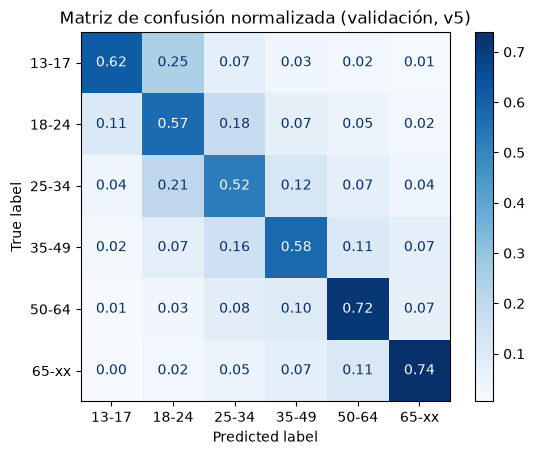

In [13]:
if VALIDAR:
    print(classification_report(yb, pred_b, labels=GROUPS, digits=3))
    ConfusionMatrixDisplay.from_predictions(yb, pred_b, labels=GROUPS, normalize='true', values_format='.2f', cmap='Blues')
    plt.title('Matriz de confusión normalizada (validación, v5)'); plt.show()

**Importancia por permutación:** se desordena cada bloque en la validación (tres repeticiones) y se mide la caída del F1. Una caída grande indica que el meta-modelo depende mucho de ese bloque. Como los bloques están correlacionados (por ejemplo, NB-SVM y nbword), un bloque puede parecer poco importante porque otro lo reemplaza.

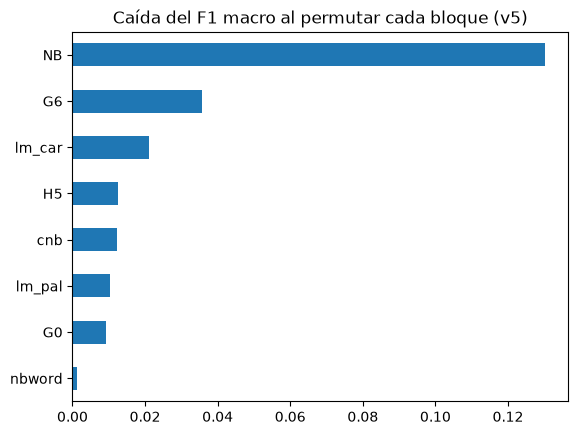

{'NB': np.float64(0.1301), 'nbword': np.float64(0.0013), 'cnb': np.float64(0.0123), 'G6': np.float64(0.0358), 'H5': np.float64(0.0127), 'G0': np.float64(0.0093), 'lm_car': np.float64(0.0211), 'lm_pal': np.float64(0.0102)}


In [14]:
if VALIDAR:
    Bs = design(FB); base_f1 = f1v(predict_seeds(META_VAL, Bs), w_val)
    cols = [c for blk in BLOCKS for c in FB[blk].columns]; imp = {}
    for blk in BLOCKS:
        idx = [cols.index(c) for c in FB[blk].columns]; drops = []
        for r in range(3):
            Pm = Bs.copy(); Pm[:, idx] = Pm[np.random.RandomState(r).permutation(len(Pm))][:, idx]
            drops.append(base_f1 - f1v(predict_seeds(META_VAL, Pm), w_val))
        imp[blk] = np.mean(drops)
    pd.Series(imp).sort_values().plot.barh(title='Caída del F1 macro al permutar cada bloque (v5)'); plt.show()
    print({k: round(v, 4) for k, v in imp.items()})

## 8. Pseudo-etiquetado (opcional)
Idea (Lee, 2013): agregar al entrenamiento los tweets del test que el modelo clasifica con mucha confianza, con su etiqueta predicha. Se probó en dos lugares, con un **umbral explícito** de probabilidad máxima ≥ `PSEUDO_TAU` = 0,90:
- **En el meta-modelo:** los tweets confiables se agregan a las filas de entrenamiento del meta-modelo.
- **En la homofilia:** sus `@cuentas`, hashtags y enlaces se suman a las tablas de G6/H5, restando la contribución del propio tweet para que su etiqueta predicha no se refuerce a sí misma.

En la partición de desarrollo las dos variantes **empeoraron** el F1 (tabla 7.1). Como verificación se mide aquí la variante menos dañina (en el meta-modelo) en la validación; aquí la validación hace el papel del test. La regla, fijada antes de correr: **se aplica al modelo final solo si mejora la validación en más de 0,002**, el ruido entre semillas medido en la v4. Se reporta cuántos tweets se agregaron.

Una explicación probable (no comprobada): los tweets con probabilidad ≥ 0,90 ya están bien clasificados (97 % de acierto en desarrollo), así que el meta-modelo aprende poco nuevo. En cambio, recibe muchas filas de las clases más fáciles y su frontera se corre hacia ellas.

In [15]:
def encode_entities_plus(tok_src, y_src, tok_app, prefix, self_src, prior=10.0):
    """Como encode_entities, pero la fuente incluye tweets pseudo-etiquetados y se resta la contribución del propio tweet
    (self_src[r] >= 0 indica que la fila r de aplicación está en la fuente), para que su etiqueta predicha no se refuerce a sí misma."""
    if isinstance(prefix, tuple):
        pat, prefix = prefix
        cv = CountVectorizer(token_pattern=pat, lowercase=True, binary=True)
    else:
        cv = CountVectorizer(analyzer=lambda x: x, binary=True)
    Xs, Xp = cv.fit_transform(tok_src), cv.transform(tok_app)
    Y = (np.asarray(y_src)[:, None] == GROUPS[None, :]).astype(np.float32)
    C = np.asarray(Xs.T @ Y); glob = Y.mean(0); S = np.asarray(Xp @ C)
    r = np.flatnonzero(self_src >= 0)
    S[r] -= np.asarray(Xp[r].sum(1)) * Y[self_src[r]]               # quitar el aporte del propio tweet
    n = S.sum(1, keepdims=True)
    P = (S + prior * glob) / (n + prior)
    out = pd.DataFrame(P, columns=[f'{prefix}_p_{c}' for c in GROUPS])
    out[f'{prefix}_edad_media'] = P @ np.arange(len(GROUPS))
    out[f'{prefix}_soporte'] = np.log1p(n.ravel())
    out[f'{prefix}_n'] = np.asarray(Xp.sum(1)).ravel()
    return out.astype(np.float32)

def homofilia_plus(T_src, y_src, R_src, T_app, R_app, self_src):
    g6 = pd.concat([encode_entities_plus(T_src, y_src, T_app, (r'@\w+', 'cta'), self_src),
                    encode_entities_plus(T_src, y_src, T_app, (r'#\w+', 'hsh'), self_src)], axis=1)
    h5 = pd.concat([encode_entities_plus(R_src[k], y_src, R_app[k], k, self_src) for k in KINDS], axis=1)
    return g6, h5

def pseudo_homofilia(T_fit, y_fit, T_app, y_ps, conf, k_folds=K_FOLDS):
    """Recalcula G6 y H5 (ajuste y aplicación) agregando a la fuente los tweets de aplicación con pseudo-etiqueta confiable."""
    T_fit, T_app = T_fit.reset_index(drop=True), T_app.reset_index(drop=True); y_fit = np.asarray(y_fit)
    folds = list(StratifiedKFold(k_folds, shuffle=True, random_state=0).split(np.zeros(len(y_fit)), y_fit))
    R_fit, R_app = relations(T_fit), relations(T_app)
    ci = np.flatnonzero(conf); Tc = T_app.iloc[ci]; yc = y_ps[ci]
    sub = lambda R, idx: {k: [R[k][i] for i in idx] for k in KINDS}
    cat = lambda R1, R2: {k: R1[k] + R2[k] for k in KINDS}
    p6, p5 = [], []
    for i, j in folds:
        f6, f5 = homofilia_plus(pd.concat([T_fit.iloc[i], Tc]), np.r_[y_fit[i], yc], cat(sub(R_fit, i), sub(R_app, ci)),
                                T_fit.iloc[j], sub(R_fit, j), np.full(len(j), -1))
        f6.index = j; f5.index = j; p6.append(f6); p5.append(f5)
    self_src = np.full(len(T_app), -1); self_src[ci] = len(T_fit) + np.arange(len(ci))
    g6b, h5b = homofilia_plus(pd.concat([T_fit, Tc]), np.r_[y_fit, yc], cat(R_fit, sub(R_app, ci)), T_app, R_app, self_src)
    return (pd.concat(p6).sort_index().reset_index(drop=True), pd.concat(p5).sort_index().reset_index(drop=True), g6b, h5b)

USAR_PSEUDO = False
if DESARROLLO:                      # reproduce las filas de pseudo-etiquetado de la tabla 7.1
    yps_d = GROUPS[(Pd * wd).argmax(1)]; Ad, Bd = design(FAd, dev_blocks), design(FBd, dev_blocks)
    for tau in (0.90, 0.80):
        conf_d = Pd.max(1) >= tau
        P1d = meta_proba(np.vstack([Ad, Bd[conf_d]]), np.r_[yd1, yps_d[conf_d]], Bd)
        g6a, h5a, g6b, h5b = pseudo_homofilia(train.text.iloc[d1], yd1, train.text.iloc[d2], yps_d, conf_d)
        A2, B2 = design(dict(FAd, G6=g6a, H5=h5a), dev_blocks), design(dict(FBd, G6=g6b, H5=h5b), dev_blocks)
        P2d = meta_proba(A2, yd1, B2)
        print(f'desarrollo τ={tau}: {conf_d.sum()} pseudo-etiquetas | meta {f1d(GROUPS[(P1d * wd).argmax(1)]):.4f}'
              f' | homofilia {f1d(GROUPS[(P2d * wd).argmax(1)]):.4f} | sin pseudo {f1d(GROUPS[(Pd * wd).argmax(1)]):.4f}')
    del FAd, FBd; gc.collect()

if VALIDAR:
    conf = P_val.max(1) >= PSEUDO_TAU; yps = GROUPS[(P_val * w_val).argmax(1)]
    log(f'Pseudo-etiquetas con probabilidad >= {PSEUDO_TAU}: {conf.sum()} de {len(conf)} tweets de validación ({conf.mean():.1%});'
        f' acierto (solo informativo) {(yps[conf] == yb[conf]).mean():.3f}')
    P_ps = meta_proba(np.vstack([design(FA), design(FB)[conf]]), np.r_[ya, yps[conf]], design(FB))
    add(f'7. + pseudo-etiquetas en el meta-modelo (τ={PSEUDO_TAU}, {conf.sum()} tweets)', f1v(P_ps, w_val))
    USAR_PSEUDO = rows[-1][1] - rows[-2][1] > PSEUDO_MIN_GAIN
    log('Se aplica el pseudo-etiquetado al modelo final:', USAR_PSEUDO)
    abl = pd.DataFrame(rows, columns=['paso', 'F1 macro']); display(abl.round(4))
    ref = dict(rows).get('2. v4: + pesos por clase (referencia v4)', 0.6193)
    v5 = dict(rows)['6. + pesos por clase (modelo v5)']
    display(pd.DataFrame({'v4': [ref], 'v5': [v5], 'diferencia': [v5 - ref]}, index=['F1 macro validación 80/20']).round(4))
    os.makedirs('resultados', exist_ok=True)
    pd.DataFrame(rows, columns=['paso', 'F1 macro']).to_csv(os.path.join('resultados', 'v5_ablacion_validacion.csv'), index=False)
    del FA, FB, META_VAL; gc.collect()

[   841s] Pseudo-etiquetas con probabilidad >= 0.9: 8767 de 33837 tweets de validación (25.9%); acierto (solo informativo) 0.977


[   913s]   7. + pseudo-etiquetas en el meta-modelo (τ=0.9, 8767 tweets) F1 = 0.6263


[   913s] Se aplica el pseudo-etiquetado al modelo final: False


,paso,F1 macro
0,(solo) LM char orden 5: log-verosimilitud + prior,0.5669
1,(solo) LM word orden 3: log-verosimilitud + prior,0.5148
2,"1. v4: K=3, 1 semilla",0.6179
3,2. v4: + pesos por clase (referencia v4),0.6193
4,3. K_FOLDS = 5,0.6193
5,"4. + LM n-grama (caracteres 5, palabras 3)",0.6231
6,5. + meta-modelo promediado en 3 semillas,0.6245
7,6. + pesos por clase (modelo v5),0.6265
8,7. + pseudo-etiquetas en el meta-modelo (τ=0.9...,0.6263


,v4,v5,diferencia
F1 macro validación 80/20,0.6193,0.6265,0.0073


## 9. Modelo final con todo el train
Se recalculan todas las entradas con el 100 % del train (fuera de muestra, 5 particiones) y con el test, se buscan los pesos por clase sobre el train y se entrena el meta-modelo con tres semillas. Luego se aplican las dos reglas de la v2/v4:
1. **Duplicados exactos:** un tweet de test idéntico a uno de train con etiqueta unánime recibe esa etiqueta.
2. **Vacíos y `#¿NOMBRE?`:** reciben la clase más frecuente de esos casos en el train.

Al final se comprueba que el archivo tenga las mismas columnas que la plantilla, una fila por tweet de test con los mismos `id` y solo clases válidas.

In [16]:
log('=== Modelo final: entradas con todo el train y el test ===')
y_all = train.age_range.values
FA, FB = build_all(train.text, y_all, test.text)
log('Pesos por clase sobre todo el train...')
w = tune_class_weights(design(FA), y_all)
print('Pesos por clase:', dict(zip(GROUPS.tolist(), w.round(2).tolist())))
P_test = meta_proba(design(FA), y_all, design(FB))
if USAR_PSEUDO:
    conf_t = P_test.max(1) >= PSEUDO_TAU; yps_t = GROUPS[(P_test * w).argmax(1)]
    P_test = meta_proba(np.vstack([design(FA), design(FB)[conf_t]]), np.r_[y_all, yps_t[conf_t]], design(FB))
    log(f'Pseudo-etiquetas agregadas al meta-modelo: {conf_t.sum()} tweets de test')
else:
    log('Pseudo-etiquetado no aplicado (no mejoró la validación): 0 tweets de test agregados')
test['age_range'] = GROUPS[(P_test * w).argmax(1)]
log('Predicciones del meta-modelo listas')

[   913s] === Modelo final: entradas con todo el train y el test ===


[   913s] TF-IDF (palabras 1-3, char_wb 2-5, char 1-5) y modelos base con 5 particiones...


[   945s]   dimensiones: [393396, 506088, 467243]


[  1127s]   NB fuera de muestra listo | memoria máx. 7.7 GB


[  1130s]   cnb fuera de muestra listo | memoria máx. 7.7 GB


...

[  1256s] Pesos por clase sobre todo el train...


[  1430s]   F1 macro fuera de muestra del meta-modelo: sin pesos 0.6213 | con pesos 0.6237


Pesos por clase: {'13-17': 0.75, '18-24': 0.95, '25-34': 1.05, '35-49': 0.9, '50-64': 0.85, '65-xx': 0.75}


[  1501s] Pseudo-etiquetado no aplicado (no mejoró la validación): 0 tweets de test agregados


[  1501s] Predicciones del meta-modelo listas


In [17]:
lab = train.groupby('text').age_range.agg(['nunique', 'first']); lookup = lab.loc[lab['nunique'] == 1, 'first']
hit = test.text.isin(lookup.index) & (test.text != '')
test.loc[hit, 'age_range'] = test.loc[hit, 'text'].map(lookup)
jt = is_junk(train_raw.text)
default = train_raw.age_range[jt].mode().iloc[0] if jt.any() else train.age_range.mode().iloc[0]
test.loc[is_junk(test.text), 'age_range'] = default
log(f'Duplicados reemplazados: {int(hit.sum())} | vacíos: {int(is_junk(test.text).sum())} -> {default}')

sp = next((os.path.join(DATA_DIR, f) for f in ('age_sample_submission.csv', 'age_submission.csv')
           if os.path.exists(os.path.join(DATA_DIR, f))), None)
cols = (pd.read_csv(sp, nrows=0, sep=None, engine='python', encoding='utf-8-sig').columns.tolist() if sp else ['id', 'age_range'])
sub = pd.DataFrame({cols[0]: test['id'].astype(int), cols[1]: test['age_range']})
sub.to_csv(OUT_PATH, index=False)

# Verificación del archivo escrito
chk = pd.read_csv(OUT_PATH, dtype={cols[1]: str})
n_test = len(pd.read_csv(os.path.join(DATA_DIR, 'age_test.csv'), sep=';', encoding='utf-8-sig', dtype=str, keep_default_na=False))
assert chk.columns.tolist() == cols, 'columnas distintas a la plantilla'
assert len(chk) == n_test == len(test), 'número de filas distinto a age_test.csv'
assert chk[cols[0]].is_unique and set(chk[cols[0]]) == set(test['id'].astype(int)), 'ids distintos a age_test.csv'
assert chk[cols[1]].isin(GROUPS).all(), 'hay clases no válidas'
print(f'Plantilla: {os.path.basename(sp) if sp else "(no encontrada)"} | columnas {cols} | filas {len(chk)} = filas de age_test.csv | clases válidas: sí')
log('Guardado:', os.path.abspath(OUT_PATH), chk.shape, f'| memoria máx. {peak_gb():.1f} GB | tiempo total {(time.time() - T0) / 60:.1f} min')
chk[cols[1]].value_counts(normalize=True).reindex(GROUPS).round(3)

[  1502s] Duplicados reemplazados: 1089 | vacíos: 99 -> 13-17


Plantilla: age_submission.csv | columnas ['id', 'age_range'] | filas 112892 = filas de age_test.csv | clases válidas: sí
[  1502s] Guardado: /Users/abelalbuez/Documents/Maestria/Cuarto Semestre/PLN/natural-language-processing-workshops/workshops/Kaggle-tweet-age/age_submission_v5.csv (112892, 2) | memoria máx. 7.7 GB | tiempo total 25.0 min


age_range
13-17    0.131
18-24    0.199
25-34    0.187
35-49    0.145
50-64    0.180
65-xx    0.158
Name: proportion, dtype: float64

## 10. Conclusiones
- **v5 supera a v4 en la misma validación 80/20 (semilla 42): 0,6265 frente a 0,6193 (+0,0073)**. La v4 se recalculó en la misma corrida, así que la comparación es pareada.
- **Los modelos de lenguaje n-grama por clase son el cambio que más aporta (+0,0039).** Solos son más débiles que NB-SVM (F1 0,567 el de caracteres y 0,515 el de palabras), pero modelan la secuencia del texto, algo que la bolsa de n-gramas no hace. En la importancia por permutación, el LM de caracteres queda tercero, después de NB-SVM y G6.
- **Pasar de 3 a 5 particiones no cambia el F1 por sí solo (0,6193 → 0,6193).** Se mantiene porque los LM y el meta-modelo se entrenan con más datos por partición, y no cuesta F1.
- **Promediar el meta-modelo en 3 semillas (+0,0014) y los pesos por clase (+0,0020) suman menos, pero de forma consistente.**
- **El pseudo-etiquetado no ayuda:** empeoró en desarrollo y en la validación quedó en −0,0002, así que el modelo final no lo usa (0 tweets de test agregados).
- **Memoria:** con 5 particiones, el NB-SVM llegó a 10 GB. Escalar las columnas directamente en float64 y calcular el TF-IDF del test al final lo bajó a 7,7 GB.
- **Próximo paso sugerido:** más semillas en el meta-modelo o promediar el NB-SVM sobre varias particiones, decidido primero en la partición de desarrollo.

## Referencias (APA 7)

Al Zamal, F., Liu, W., & Ruths, D. (2012). Homophily and latent attribute inference: Inferring latent attributes of Twitter users from neighbors. *Proceedings of the International AAAI Conference on Web and Social Media, 6*(1), 387–390.

Chen, S. F., & Goodman, J. (1999). An empirical study of smoothing techniques for language modeling. *Computer Speech & Language, 13*(4), 359–394.

Fernández Huerta, J. (1959). Medidas sencillas de lecturabilidad. *Consigna, 214*, 29–32.

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232.

Kneser, R., & Ney, H. (1995). Improved backing-off for M-gram language modeling. En *1995 International Conference on Acoustics, Speech, and Signal Processing* (Vol. 1, pp. 181–184). IEEE.

Lee, D.-H. (2013). Pseudo-label: The simple and efficient semi-supervised learning method for deep neural networks. En *ICML 2013 Workshop on Challenges in Representation Learning*.

McPherson, M., Smith-Lovin, L., & Cook, J. M. (2001). Birds of a feather: Homophily in social networks. *Annual Review of Sociology, 27*, 415–444.

Micci-Barreca, D. (2001). A preprocessing scheme for high-cardinality categorical attributes in classification and prediction problems. *ACM SIGKDD Explorations Newsletter, 3*(1), 27–32.

Peng, F., Schuurmans, D., Wang, S., & Keselj, V. (2003). Language independent authorship attribution using character level language models. En *Proceedings of the 10th Conference of the European Chapter of the Association for Computational Linguistics* (pp. 267–274).

Rennie, J. D. M., Shih, L., Teevan, J., & Karger, D. R. (2003). Tackling the poor assumptions of naive Bayes text classifiers. En *Proceedings of the 20th International Conference on Machine Learning* (pp. 616–623).

Szigriszt Pazos, F. (1993). *Sistemas predictivos de legibilidad del mensaje escrito: Fórmula de perspicuidad* [Tesis doctoral, Universidad Complutense de Madrid].

Wang, S., & Manning, C. D. (2012). Baselines and bigrams: Simple, good sentiment and topic classification. En *Proceedings of the 50th Annual Meeting of the Association for Computational Linguistics* (Vol. 2, pp. 90–94).

Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241–259.